In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("../Ontrac_data.csv")

# Clean column names and text values
df.columns = df.columns.str.strip()

df["Invoice_Date"] = pd.to_datetime(
    df["Invoice_Date"], errors="coerce"
)

df["Client"] = df["Client"].astype("string").str.strip()
df["Products"] = df["Products"].astype("string").str.strip()
df["Bank_Document"] = df["Bank_Document"].astype("string").str.strip()

# Convert Amount to numeric
df["Amount"] = pd.to_numeric(df["Amount"], errors="coerce")

# Remove rows missing key analysis fields
df = df.dropna(subset=["Client", "Products", "Amount"])

# Standardize text to combine capitalization variations
df["Client"] = df["Client"].str.upper()
df["Products"] = df["Products"].str.upper()

# Optional: remove duplicate invoice rows only if you have
# a reliable invoice identifier to identify true duplicates.

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (12, 6)

print(df.head())
print("Dataset shape:", df.shape)
print("Total revenue:", df["Amount"].sum())

  Invoice_Date               Client                      Products    Amount  \
0   2025-09-02              NOVAQUA      SIKACERAM 80I WHITE+GREY  21420.00   
1   2025-09-08   MY DE CONSTRUCTION           REBAR 08 TOR FE 500  11144.00   
2   2025-09-17          TERRASTRUCT  CEMENT CPJ35 (21 T +19 BAGS)  36790.00   
3   2025-09-22  STE DERRAB LISSAKAN    SIKACERAM 80I WHITE + GREY   4998.68   
4   2025-09-23  STE DERRAB LISSAKAN    WOOD TALK LOUVERS 200X1200   4999.60   

                      Bank_Document  
0                 TRANSFER RECEIVED  
1  COLLECTION OF 1 BILL OF EXCHANGE  
2                 TRANSFER RECEIVED  
3           OFF-BRANCH CASH DEPOSIT  
4           OFF-BRANCH CASH DEPOSIT  
Dataset shape: (147, 5)
Total revenue: 2631081.88


In [3]:
summary = (
    df.groupby(["Client", "Products"], as_index=False)
      .agg(
          Total_Revenue=("Amount", "sum"),
          Average_Invoice=("Amount", "mean"),
          Transaction_Count=("Amount", "size"),
          Highest_Invoice=("Amount", "max"),
          Lowest_Invoice=("Amount", "min"),
          Invoice_Std=("Amount", "std")
      )
)

summary.sort_values("Total_Revenue", ascending=False)

,Client,Products,Total_Revenue,Average_Invoice,Transaction_Count,Highest_Invoice,Lowest_Invoice,Invoice_Std
39,NOVAQUA,CEMENT CPJ35 (27 T),201420.0,40284.0,5,40500.0,40230.0,120.747671
42,NOVAQUA,CEMENT CPJ35 (28 T),199230.0,39846.0,5,41720.0,32350.0,4190.391390
49,SCADACOM MAROC,CIMARPRO 35 (27 T),162300.0,40575.0,4,41040.0,40230.0,410.243830
40,NOVAQUA,CEMENT CPJ35 (27 T)+ PROLIDAL,120690.0,40230.0,3,40230.0,40230.0,0.000000
43,NOVAQUA,CEMENT CPJ35 (29 T),86420.0,43210.0,2,43210.0,43210.0,0.000000
...,...,...,...,...,...,...,...,...
57,STE ARAFIK,REBAR 05 SMOOTH,2800.0,2800.0,1,2800.0,2800.0,NaN
14,DISTRAC,WEBERCOL CLASSIC GREY+WHITE,2725.0,2725.0,1,2725.0,2725.0,NaN
12,DISTRAC,HAMRI ADHESIVE GREY C1 25KG,2700.0,2700.0,1,2700.0,2700.0,NaN
25,FAHMI ABDELJALIL,SIKACERAM 80I+HAMRI ADHESIVE,2592.0,2592.0,1,2592.0,2592.0,NaN


## 1. Which client–product combinations generate the highest total revenue?

In [4]:
q1_stats = (
    df.groupby(["Client", "Products"])["Amount"]
      .agg(Total_Revenue="sum", Transaction_Count="count")
      .reset_index()
      .sort_values("Total_Revenue", ascending=False)
)

q1_stats.head(10)

,Client,Products,Total_Revenue,Transaction_Count
39,NOVAQUA,CEMENT CPJ35 (27 T),201420.0,5
42,NOVAQUA,CEMENT CPJ35 (28 T),199230.0,5
49,SCADACOM MAROC,CIMARPRO 35 (27 T),162300.0,4
40,NOVAQUA,CEMENT CPJ35 (27 T)+ PROLIDAL,120690.0,3
43,NOVAQUA,CEMENT CPJ35 (29 T),86420.0,2
32,MESWANE,CIMARPRO 35 (27 T),82080.0,2
45,NOVAQUA,CIMARPRO 35 (27 T),81270.0,2
38,NA MEGA S&C,CIMARPRO 35 (27 T),80460.0,2
23,ENT FAJER TAIBA,SIKACERAM 80I GREY + PROLIDAL,54185.0,2
52,STE AF.ED,SIKACERAM 80I + HAMRI ADHESIVE,48500.0,1


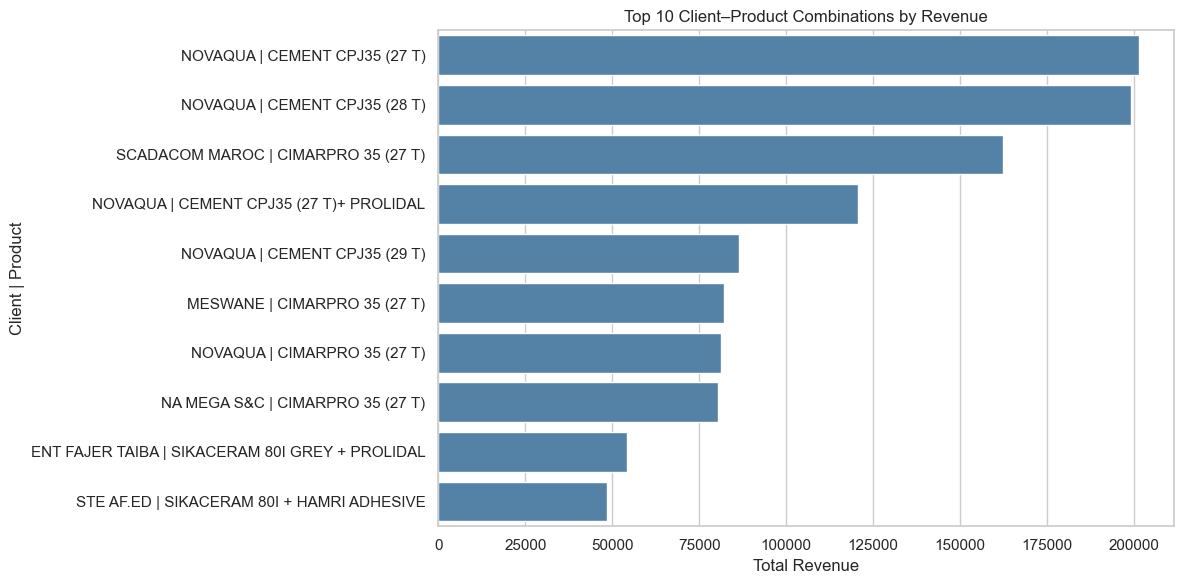

In [5]:
q1_plot = q1_stats.head(10).copy()
q1_plot["Combination"] = (
    q1_plot["Client"] + " | " + q1_plot["Products"]
)

plt.figure(figsize=(12, 6))
sns.barplot(data=q1_plot, x="Total_Revenue", y="Combination",
            color="steelblue")

plt.title("Top 10 Client–Product Combinations by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Client | Product")
plt.tight_layout()
plt.show()

## 2. Which clients spend the most on each product?

    #The Products column represents the product name,  
    #Client identifies the highest-spending client for that product. 
    #Total_Spending indicates the total amount spent by that client on the product.
    #Pct_of_Product_Spending shows the percentage of the total spending on that particular product contributed by the client, 
    #Pct_of_Overall_Spending represents the percentage of total spending across all products and clients accounted for by that client's spending on the product.




In [10]:
q2_stats = (
    df.groupby(["Products", "Client"])["Amount"]
      .sum()
      .reset_index(name="Total_Spending")
)

# Top-spending client for each product
q2_top = q2_stats.loc[
    q2_stats.groupby("Products")["Total_Spending"].idxmax()
].copy()

# Total spending for each product
product_totals = q2_stats.groupby("Products")["Total_Spending"].sum()

# Overall spending across all products and clients
overall_total = q2_stats["Total_Spending"].sum()

# Percentage of total spending for that product
q2_top["Pct_of_Product_Spending"] = (
    q2_top["Total_Spending"]
    / q2_top["Products"].map(product_totals)
) * 100

# Percentage of overall spending
q2_top["Pct_of_Overall_Spending"] = (
    q2_top["Total_Spending"] / overall_total
) * 100

# Sort and round percentages
q2_top = q2_top.sort_values(
    "Total_Spending", ascending=False
).round({
    "Pct_of_Product_Spending": 2,
    "Pct_of_Overall_Spending": 2
})

q2_top = q2_top.reset_index(drop=True)


    #The Products column represents the product name,  
    #Client identifies the highest-spending client for that product. 
    #Total_Spending indicates the total amount spent by that client on the product.
    #Pct_of_Product_Spending shows the percentage of the total spending on that particular product contributed by the client, 
    #Pct_of_Overall_Spending represents the percentage of total spending across all products and clients accounted for by that client's spending on the product.
q2_top

,Products,Client,Total_Spending,Pct_of_Product_Spending,Pct_of_Overall_Spending
0,CEMENT CPJ35 (27 T),NOVAQUA,201420.00,62.48,7.66
1,CEMENT CPJ35 (28 T),NOVAQUA,199230.00,100.00,7.57
2,CIMARPRO 35 (27 T),SCADACOM MAROC,162300.00,36.26,6.17
3,CEMENT CPJ35 (27 T)+ PROLIDAL,NOVAQUA,120690.00,75.00,4.59
4,CEMENT CPJ35 (29 T),NOVAQUA,86420.00,100.00,3.28
5,SIKACERAM 80I GREY + PROLIDAL,ENT FAJER TAIBA,54185.00,100.00,2.06
6,SIKACERAM 80I + HAMRI ADHESIVE,STE AF.ED,48500.00,100.00,1.84
7,SIKACERAM 80I WHITE+GREY+REBAR 10 TOR,STE RACHIDIA CARREAUX,45600.00,100.00,1.73
8,SIKACERAM 80I WHITE+GREY,STE RACHIDIA CARREAUX,44800.00,67.65,1.70
9,CIMARPRO 35,ELIPROMO,42080.00,100.00,1.60


## 3. Which products generate the highest average invoice value for each client?

In [11]:
q3_stats = (
    df.groupby(["Client", "Products"])["Amount"]
      .agg(
          Average_Invoice="mean",
          Median_Invoice="median",
          Transaction_Count="count"
      )
      .reset_index()
)

q3_top = q3_stats.loc[
    q3_stats.groupby("Client")["Average_Invoice"].idxmax()
]

q3_top.sort_values("Average_Invoice", ascending=False)

,Client,Products,Average_Invoice,Median_Invoice,Transaction_Count
52,STE AF.ED,SIKACERAM 80I + HAMRI ADHESIVE,48500.00,48500.00,1
80,STE RACHIDIA CARREAUX,SIKACERAM 80I WHITE+GREY+REBAR 10 TOR,45600.00,45600.00,1
43,NOVAQUA,CEMENT CPJ35 (29 T),43210.00,43210.00,2
18,ELIPROMO,CIMARPRO 35,42080.00,42080.00,1
78,STE OULAD ZAERS PROMO,CIMARPRO 35 (27 T),41445.00,41445.00,1
50,SCADACOM MAROC,CIMARPRO 45 (27 T),41310.00,41310.00,1
32,MESWANE,CIMARPRO 35 (27 T),41040.00,41040.00,2
11,DAIMON IMMO,CEMENT CPJ35 (27 T),40500.00,40500.00,1
38,NA MEGA S&C,CIMARPRO 35 (27 T),40230.00,40230.00,2
30,MESTRACO,CEMENT CPJ35 (27 T),40230.00,40230.00,1


## 4. Are high-value transactions concentrated around particular client–product combinations?

In [12]:
threshold = df["Amount"].quantile(0.75)

df["High_Value"] = df["Amount"] > threshold

q4_stats = (
    df.groupby(["Client", "Products"])
      .agg(
          Total_Transactions=("Amount", "size"),
          High_Value_Count=("High_Value", "sum"),
          Total_Revenue=("Amount", "sum")
      )
      .reset_index()
)

q4_stats["High_Value_Percentage"] = (
    q4_stats["High_Value_Count"] /
    q4_stats["Total_Transactions"] * 100
)

q4_stats = q4_stats.sort_values(
    ["High_Value_Count", "High_Value_Percentage"],
    ascending=False
)

print("High-value threshold:", threshold)
q4_stats.head(10)

High-value threshold: 40230.0


,Client,Products,Total_Transactions,High_Value_Count,Total_Revenue,High_Value_Percentage
42,NOVAQUA,CEMENT CPJ35 (28 T),5,4,199230.0,80.0
32,MESWANE,CIMARPRO 35 (27 T),2,2,82080.0,100.0
43,NOVAQUA,CEMENT CPJ35 (29 T),2,2,86420.0,100.0
49,SCADACOM MAROC,CIMARPRO 35 (27 T),4,2,162300.0,50.0
11,DAIMON IMMO,CEMENT CPJ35 (27 T),1,1,40500.0,100.0
16,ELIPROMO,CEMENT CPJ35+ REBAR 12 TOR,1,1,41600.0,100.0
17,ELIPROMO,CEMENT CPJ35+REBAR 12 TOR,1,1,41445.0,100.0
18,ELIPROMO,CIMARPRO 35,1,1,42080.0,100.0
19,ELIPROMO,CIMARPRO 35 (27 T)+ REBAR 05 SMOOTH,1,1,42080.0,100.0
33,MESWANE,CIMARPRO 45+35,1,1,40345.0,100.0


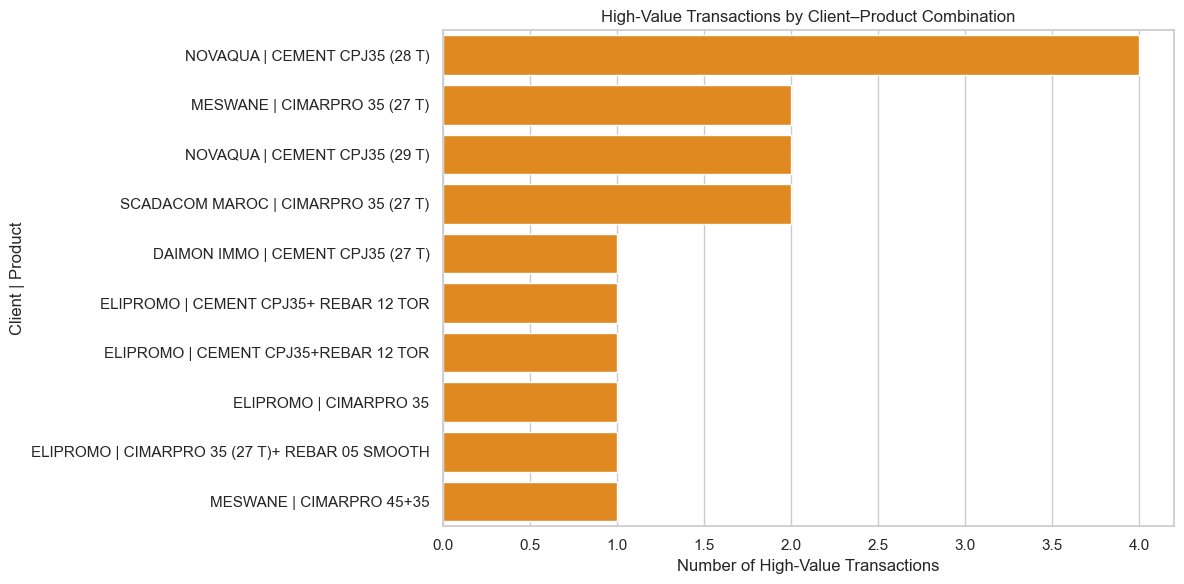

In [13]:
q4_plot = q4_stats.nlargest(10, "High_Value_Count").copy()
q4_plot["Combination"] = (
    q4_plot["Client"] + " | " + q4_plot["Products"]
)

plt.figure(figsize=(12, 6))
sns.barplot(data=q4_plot, x="High_Value_Count", y="Combination",
            color="darkorange")

plt.title("High-Value Transactions by Client–Product Combination")
plt.xlabel("Number of High-Value Transactions")
plt.ylabel("Client | Product")
plt.tight_layout()
plt.show()

## 5. Which client–product combinations have the most transactions?

In [14]:
q5_stats = (
    df.groupby(["Client", "Products"])
      .size()
      .reset_index(name="Transaction_Count")
      .sort_values("Transaction_Count", ascending=False)
)

q5_stats.head(10)

,Client,Products,Transaction_Count
6,AYOUB MARRAKECH,WEBERCOL CLASSIC GREY,7
60,STE ARAFIK,SIKACERAM 80I+HAMRI ADHESIVE,7
8,AYOUB MARRAKECH,WEBERCOL CLASSIC WHITE,6
63,STE ARAFIK,WEBERCOL CLASSIC WHITE,6
42,NOVAQUA,CEMENT CPJ35 (28 T),5
39,NOVAQUA,CEMENT CPJ35 (27 T),5
74,STE DERRAB LISSAKAN,SIKACERAM 80I WHITE + GREY,5
73,STE DERRAB LISSAKAN,SIKACERAM 80I WHITE,4
49,SCADACOM MAROC,CIMARPRO 35 (27 T),4
69,STE DERRAB LISSAKAN,SIKACERAM 100M GREY,4


## 6. Which clients contribute the largest percentage of total revenue for each product?

In [15]:
q6_stats = (
    df.groupby(["Products", "Client"])["Amount"]
      .sum()
      .reset_index(name="Client_Revenue")
)

q6_stats["Product_Revenue"] = (
    q6_stats.groupby("Products")["Client_Revenue"].transform("sum")
)

q6_stats["Revenue_Share_Percent"] = (
    q6_stats["Client_Revenue"] /
    q6_stats["Product_Revenue"] * 100
)

q6_stats = q6_stats.sort_values(
    ["Products", "Revenue_Share_Percent"],
    ascending=[True, False]
)

q6_stats

,Products,Client,Client_Revenue,Product_Revenue,Revenue_Share_Percent
0,CEMENT CPJ35,EMRAUDE PARK,40000.00,40000.00,100.000000
1,CEMENT CPJ35 (21 T +19 BAGS),TERRASTRUCT,36790.00,36790.00,100.000000
4,CEMENT CPJ35 (27 T),NOVAQUA,201420.00,322380.00,62.479062
2,CEMENT CPJ35 (27 T),DAIMON IMMO,40500.00,322380.00,12.562814
3,CEMENT CPJ35 (27 T),MESTRACO,40230.00,322380.00,12.479062
...,...,...,...,...,...
82,WEBERCOL DUR WHITE,AYOUB MARRAKECH,9995.62,9995.62,100.000000
83,WEBERCOL DUR+CLASSIC,EMTAC,14239.00,14239.00,100.000000
84,WEBERCOL DUR+JUNTA FINA+CLASSIC GREY,AYOUB MARRAKECH,4994.29,4994.29,100.000000
85,WEBERCOL TOP WHITE,STE RACHIDIA CARREAUX,8600.00,8600.00,100.000000


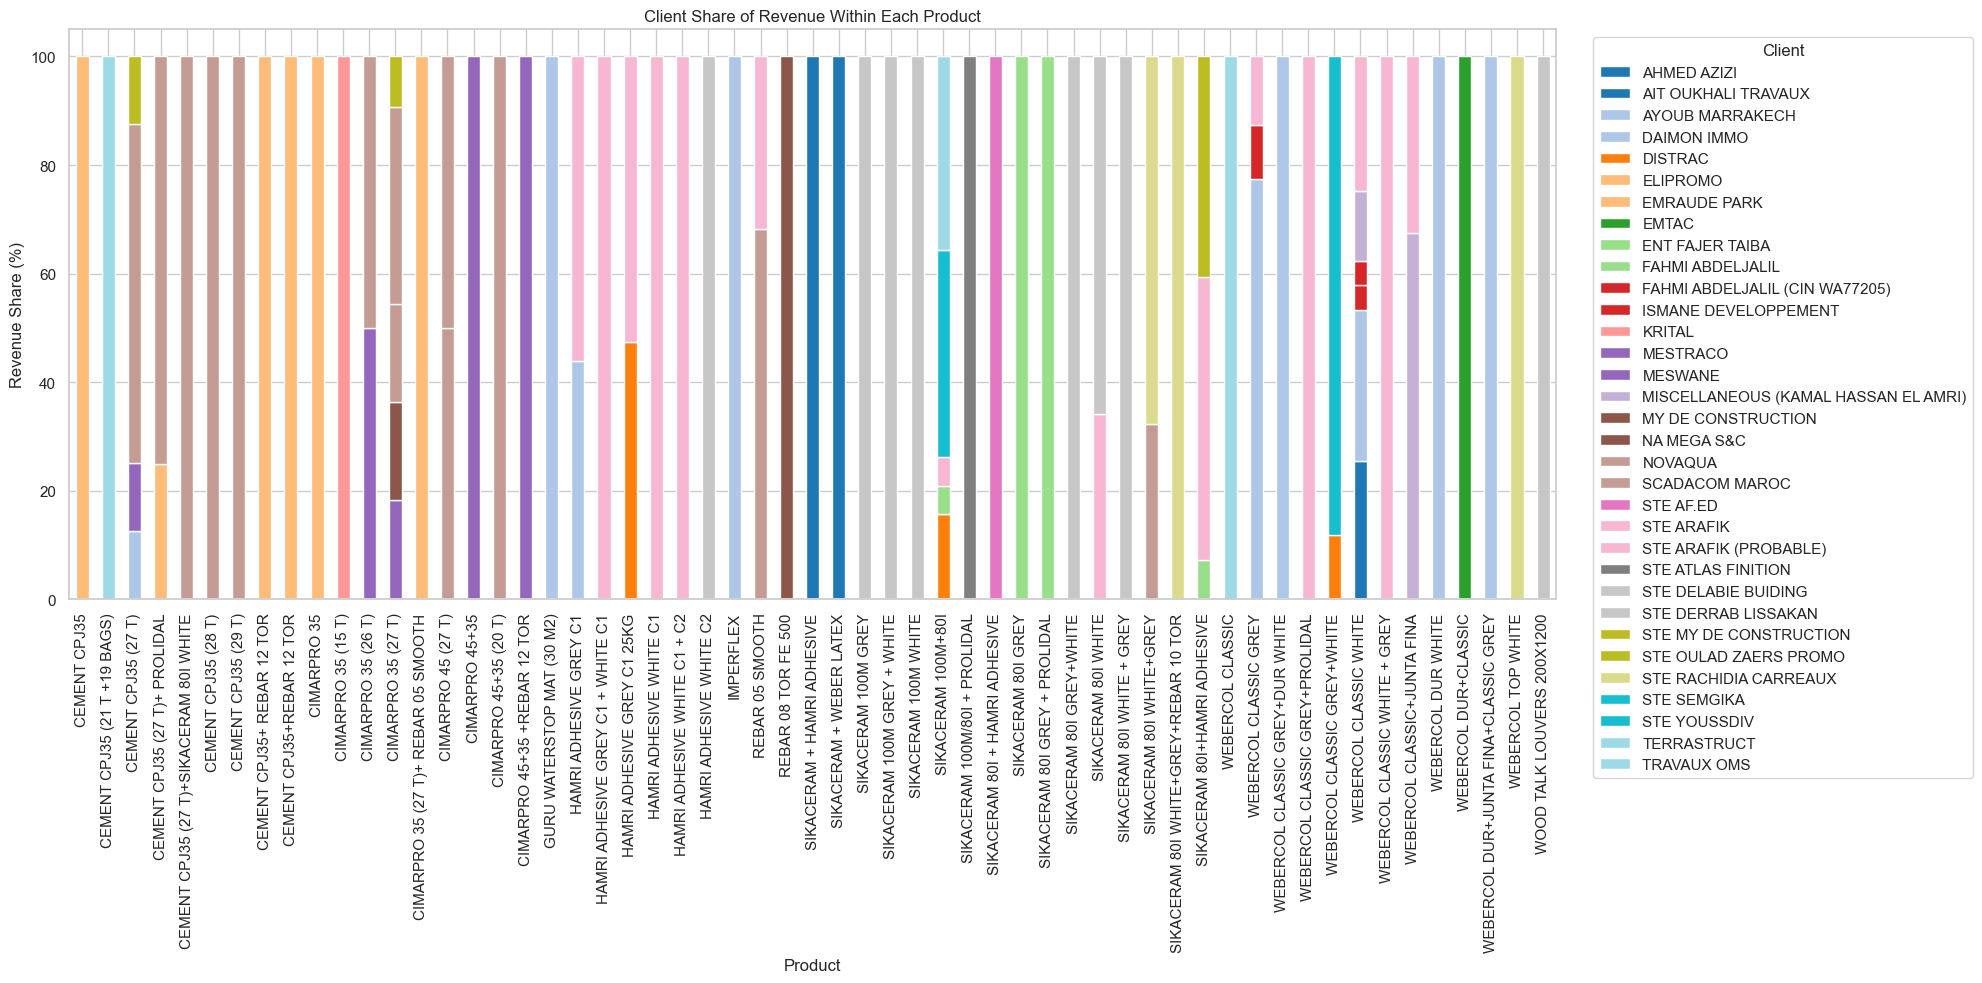

In [17]:
q6_pivot = q6_stats.pivot(
    index="Products",
    columns="Client",
    values="Revenue_Share_Percent"
).fillna(0)

q6_pivot.plot(kind="bar", stacked=True, figsize=(20, 10),
              colormap="tab20")

plt.title("Client Share of Revenue Within Each Product")
plt.xlabel("Product")
plt.ylabel("Revenue Share (%)")
plt.legend(title="Client", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 7. Which products account for the largest share of each client's total spending?

In [18]:
q7_stats = (
    df.groupby(["Client", "Products"])["Amount"]
      .sum()
      .reset_index(name="Product_Revenue")
)

q7_stats["Client_Total_Spending"] = (
    q7_stats.groupby("Client")["Product_Revenue"].transform("sum")
)

q7_stats["Spending_Share_Percent"] = (
    q7_stats["Product_Revenue"] /
    q7_stats["Client_Total_Spending"] * 100
)

q7_top = q7_stats.loc[
    q7_stats.groupby("Client")["Spending_Share_Percent"].idxmax()
]

q7_top.sort_values("Spending_Share_Percent", ascending=False)

,Client,Products,Product_Revenue,Client_Total_Spending,Spending_Share_Percent
0,AHMED AZIZI,WEBERCOL CLASSIC WHITE,24900.00,24900.00,100.000000
11,DAIMON IMMO,CEMENT CPJ35 (27 T),40500.00,40500.00,100.000000
20,EMRAUDE PARK,CEMENT CPJ35,40000.00,40000.00,100.000000
21,EMTAC,WEBERCOL DUR+CLASSIC,14239.00,14239.00,100.000000
26,FAHMI ABDELJALIL (CIN WA77205),WEBERCOL CLASSIC WHITE,4413.21,4413.21,100.000000
30,MESTRACO,CEMENT CPJ35 (27 T),40230.00,40230.00,100.000000
37,MY DE CONSTRUCTION,REBAR 08 TOR FE 500,11144.00,11144.00,100.000000
29,KRITAL,CIMARPRO 35 (15 T),23328.00,23328.00,100.000000
82,STE SEMGIKA,SIKACERAM 100M+80I,30000.00,30000.00,100.000000
76,STE MY DE CONSTRUCTION,SIKACERAM 80I+HAMRI ADHESIVE,14500.00,14500.00,100.000000


## 8. Which client–product combinations have the highest and lowest invoice amounts?

In [24]:
q8_stats = (
    df.groupby(["Client", "Products"])["Amount"]
      .agg(
          Highest_Invoice="max",
          Lowest_Invoice="min",
          Average_Invoice="mean"
      )
      .reset_index()
)

print("Highest invoice amounts:")
q8_stats.nlargest(10, "Highest_Invoice")



Highest invoice amounts:


,Client,Products,Highest_Invoice,Lowest_Invoice,Average_Invoice
52,STE AF.ED,SIKACERAM 80I + HAMRI ADHESIVE,48500.0,48500.0,48500.0
80,STE RACHIDIA CARREAUX,SIKACERAM 80I WHITE+GREY+REBAR 10 TOR,45600.0,45600.0,45600.0
79,STE RACHIDIA CARREAUX,SIKACERAM 80I WHITE+GREY,44800.0,44800.0,44800.0
43,NOVAQUA,CEMENT CPJ35 (29 T),43210.0,43210.0,43210.0
18,ELIPROMO,CIMARPRO 35,42080.0,42080.0,42080.0
19,ELIPROMO,CIMARPRO 35 (27 T)+ REBAR 05 SMOOTH,42080.0,42080.0,42080.0
41,NOVAQUA,CEMENT CPJ35 (27 T)+SIKACERAM 80I WHITE,41720.0,41720.0,41720.0
42,NOVAQUA,CEMENT CPJ35 (28 T),41720.0,32350.0,39846.0
16,ELIPROMO,CEMENT CPJ35+ REBAR 12 TOR,41600.0,41600.0,41600.0
17,ELIPROMO,CEMENT CPJ35+REBAR 12 TOR,41445.0,41445.0,41445.0


In [25]:
print("\nLowest invoice amounts:")
q8_stats.nsmallest(10, "Lowest_Invoice")


Lowest invoice amounts:


,Client,Products,Highest_Invoice,Lowest_Invoice,Average_Invoice
59,STE ARAFIK,SIKACERAM 80I WHITE,4992.00,384.00,3456.000000
63,STE ARAFIK,WEBERCOL CLASSIC WHITE,4998.24,2160.00,4052.160000
62,STE ARAFIK,WEBERCOL CLASSIC GREY+PROLIDAL,2502.00,2502.00,2502.000000
25,FAHMI ABDELJALIL,SIKACERAM 80I+HAMRI ADHESIVE,2592.00,2592.00,2592.000000
60,STE ARAFIK,SIKACERAM 80I+HAMRI ADHESIVE,3052.00,2592.00,2657.714286
12,DISTRAC,HAMRI ADHESIVE GREY C1 25KG,2700.00,2700.00,2700.000000
14,DISTRAC,WEBERCOL CLASSIC GREY+WHITE,2725.00,2725.00,2725.000000
57,STE ARAFIK,REBAR 05 SMOOTH,2800.00,2800.00,2800.000000
7,AYOUB MARRAKECH,WEBERCOL CLASSIC GREY+DUR WHITE,2964.38,2964.38,2964.380000
66,STE ARAFIK (PROBABLE),HAMRI ADHESIVE GREY C1 25KG,3000.00,3000.00,3000.000000


## 9. Do certain clients consistently purchase products at higher invoice values than other clients?

In [26]:
q9_stats = (
    df.groupby(["Products", "Client"])["Amount"]
      .agg(
          Average_Invoice="mean",
          Median_Invoice="median",
          Transaction_Count="count"
      )
      .reset_index()
)

q9_stats = q9_stats.sort_values(
    ["Products", "Average_Invoice"],
    ascending=[True, False]
)

q9_stats

,Products,Client,Average_Invoice,Median_Invoice,Transaction_Count
0,CEMENT CPJ35,EMRAUDE PARK,40000.00,40000.00,1
1,CEMENT CPJ35 (21 T +19 BAGS),TERRASTRUCT,36790.00,36790.00,1
2,CEMENT CPJ35 (27 T),DAIMON IMMO,40500.00,40500.00,1
4,CEMENT CPJ35 (27 T),NOVAQUA,40284.00,40230.00,5
3,CEMENT CPJ35 (27 T),MESTRACO,40230.00,40230.00,1
...,...,...,...,...,...
82,WEBERCOL DUR WHITE,AYOUB MARRAKECH,4997.81,4997.81,2
83,WEBERCOL DUR+CLASSIC,EMTAC,14239.00,14239.00,1
84,WEBERCOL DUR+JUNTA FINA+CLASSIC GREY,AYOUB MARRAKECH,4994.29,4994.29,1
85,WEBERCOL TOP WHITE,STE RACHIDIA CARREAUX,8600.00,8600.00,1


## 10. Which client–product combinations show the greatest variation in invoice amounts, and which are the most consistent?

In [30]:
q10_stats = (
    df.groupby(["Client", "Products"])["Amount"]
      .agg(
          Average_Invoice="mean",
          Median_Invoice="median",
          Std_Deviation="std",
          Transaction_Count="count"
      )
      .reset_index()
)

q10_stats["CV_Percent"] = (
    q10_stats["Std_Deviation"] /
    q10_stats["Average_Invoice"].abs() * 100
)

q10_valid = q10_stats[
    (q10_stats["Transaction_Count"] >= 2) &
    (q10_stats["Average_Invoice"] != 0)
].copy()

print("Most variable combinations:")
print("Standard deviation measures absolute variability.") 
print("The coefficient of variation (CV) measures variability relative to the mean")
q10_valid.nlargest(10, "Std_Deviation")



Most variable combinations:
Standard deviation measures absolute variability.
The coefficient of variation (CV) measures variability relative to the mean


,Client,Products,Average_Invoice,Median_Invoice,Std_Deviation,Transaction_Count,CV_Percent
23,ENT FAJER TAIBA,SIKACERAM 80I GREY + PROLIDAL,27092.500000,27092.50,6409.922971,2,23.659400
42,NOVAQUA,CEMENT CPJ35 (28 T),39846.000000,41720.00,4190.391390,5,10.516467
59,STE ARAFIK,SIKACERAM 80I WHITE,3456.000000,4992.00,2660.430040,3,76.980036
63,STE ARAFIK,WEBERCOL CLASSIC WHITE,4052.160000,4998.24,1465.660834,6,36.169866
45,NOVAQUA,CIMARPRO 35 (27 T),40635.000000,40635.00,572.756493,2,1.409515
71,STE DERRAB LISSAKAN,SIKACERAM 100M WHITE,4652.360000,4652.36,490.279558,2,10.538298
6,AYOUB MARRAKECH,WEBERCOL CLASSIC GREY,4372.528571,4178.50,438.156339,7,10.020663
49,SCADACOM MAROC,CIMARPRO 35 (27 T),40575.000000,40515.00,410.243830,4,1.011075
8,AYOUB MARRAKECH,WEBERCOL CLASSIC WHITE,4555.133333,4550.72,245.260380,6,5.384263
60,STE ARAFIK,SIKACERAM 80I+HAMRI ADHESIVE,2657.714286,2592.00,173.863658,7,6.541849


In [31]:
print("\nMost consistent combinations:")
print("The coefficient of variation (CV) measures variability relative to the mean")
q10_valid.nsmallest(10, "CV_Percent")


Most consistent combinations:
The coefficient of variation (CV) measures variability relative to the mean


,Client,Products,Average_Invoice,Median_Invoice,Std_Deviation,Transaction_Count,CV_Percent
3,AYOUB MARRAKECH,GURU WATERSTOP MAT (30 M2),4800.00,4800.00,0.0,4,0.0
9,AYOUB MARRAKECH,WEBERCOL DUR WHITE,4997.81,4997.81,0.0,2,0.0
13,DISTRAC,SIKACERAM 100M+80I,4110.40,4110.40,0.0,3,0.0
32,MESWANE,CIMARPRO 35 (27 T),41040.00,41040.00,0.0,2,0.0
38,NA MEGA S&C,CIMARPRO 35 (27 T),40230.00,40230.00,0.0,2,0.0
40,NOVAQUA,CEMENT CPJ35 (27 T)+ PROLIDAL,40230.00,40230.00,0.0,3,0.0
43,NOVAQUA,CEMENT CPJ35 (29 T),43210.00,43210.00,0.0,2,0.0
65,STE ARAFIK,WEBERCOL CLASSIC+JUNTA FINA,4320.00,4320.00,0.0,2,0.0
69,STE DERRAB LISSAKAN,SIKACERAM 100M GREY,4999.28,4999.28,0.0,4,0.0
73,STE DERRAB LISSAKAN,SIKACERAM 80I WHITE,4999.68,4999.68,0.0,4,0.0
